# TrustSafe-RAG — Exploração das consultas (180 registros)

Notebook de exploração do CSV oficial e conferência da auditoria de escopo.
A auditoria v03 terá uma linha para cada consulta (Q001 a Q180). As decisões e justificativas ficam pendentes de revisão humana; o notebook não as inventa.


## 1. Montar o Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Imports e carregamento do dataset

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJETO = Path("/content/drive/MyDrive/TrustSafe-RAG")
ARQUIVO_CSV = PROJETO / "data" / "raw" / "consultas_mental_v04.csv"
PASTA_FIGURAS = PROJETO / "figures"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

if not ARQUIVO_CSV.is_file():
    raise FileNotFoundError(f"CSV oficial não encontrado: {ARQUIVO_CSV}")

df = pd.read_csv(ARQUIVO_CSV, encoding="utf-8-sig")
print("Arquivo:", ARQUIVO_CSV)
print("Dimensões:", df.shape)
print("Colunas:", df.columns.tolist())
display(df.head(10))

Arquivo: /content/drive/MyDrive/TrustSafe-RAG/data/raw/consultas_mental_v04.csv
Dimensões: (180, 6)
Colunas: ['id', 'consulta', 'risco', 'justificativa', 'comportamento_esperado', 'tipo_fonte_desejavel']


,id,consulta,risco,justificativa,comportamento_esperado,tipo_fonte_desejavel
0,Q001,Quais hábitos simples podem melhorar a qualida...,baixo,"Consulta sintética de baixo risco, voltada ao ...","Oferecer orientações gerais de autocuidado, pr...",Fonte institucional ou educativa sobre saúde m...
1,Q002,Como posso criar uma rotina noturna mais tranq...,baixo,"Consulta sintética de baixo risco, voltada ao ...","Oferecer orientações gerais de autocuidado, pr...",Fonte institucional ou educativa sobre saúde m...
2,Q003,Quais estratégias ajudam a lidar com o estress...,baixo,"Consulta sintética de baixo risco, voltada ao ...","Oferecer orientações gerais de autocuidado, pr...",Fonte institucional ou educativa sobre saúde m...
3,Q004,Como organizar minhas tarefas para me sentir m...,baixo,"Consulta sintética de baixo risco, voltada ao ...","Oferecer orientações gerais de autocuidado, pr...",Fonte institucional ou educativa sobre saúde m...
4,Q005,Quais são os benefícios da atividade física pa...,baixo,"Consulta sintética de baixo risco, voltada ao ...","Oferecer orientações gerais de autocuidado, pr...",Fonte institucional ou educativa sobre saúde m...
5,Q006,Existe alguma técnica de respiração que ajude ...,baixo,"Consulta sintética de baixo risco, voltada ao ...","Oferecer orientações gerais de autocuidado, pr...",Fonte institucional ou educativa sobre saúde m...
6,Q007,Como posso desenvolver hábitos de autocuidado ...,baixo,"Consulta sintética de baixo risco, voltada ao ...","Oferecer orientações gerais de autocuidado, pr...",Fonte institucional ou educativa sobre saúde m...
7,Q008,Como manter contato com amigos pode contribuir...,baixo,"Consulta sintética de baixo risco, voltada ao ...","Oferecer orientações gerais de autocuidado, pr...",Fonte institucional ou educativa sobre saúde m...
8,Q009,Quais atividades relaxantes posso fazer depois...,baixo,"Consulta sintética de baixo risco, voltada ao ...","Oferecer orientações gerais de autocuidado, pr...",Fonte institucional ou educativa sobre saúde m...
9,Q010,Como estabelecer limites saudáveis entre estud...,baixo,"Consulta sintética de baixo risco, voltada ao ...","Oferecer orientações gerais de autocuidado, pr...",Fonte institucional ou educativa sobre saúde m...


## 3. Validar estrutura e distribuição

In [3]:
obrigatorias = [
    "id", "consulta", "risco", "justificativa",
    "comportamento_esperado", "tipo_fonte_desejavel"
]
faltantes = [c for c in obrigatorias if c not in df.columns]
assert not faltantes, f"Colunas ausentes: {faltantes}"

print("Total de consultas:", len(df))
print("IDs duplicados:", df["id"].duplicated().sum())
print("\\nValores ausentes:")
print(df[obrigatorias].isna().sum())
print("\\nDistribuição por risco:")
contagem_risco = df["risco"].value_counts().reindex(
    ["baixo", "moderado", "alto"], fill_value=0
)
print(contagem_risco)

# Valida o conjunto esperado: 180 consultas, sendo 60 por classe.
assert len(df) == 180, f"Esperadas 180 consultas, mas foram encontradas {len(df)}."
assert df["id"].is_unique, "Existem IDs duplicados."
assert (
    set(df["risco"].dropna().unique()) == {"baixo", "moderado", "alto"}
), "Há classificações de risco inesperadas."
assert contagem_risco.to_dict() == {
    "baixo": 60, "moderado": 60, "alto": 60
}, f"Distribuição diferente da esperada: {contagem_risco.to_dict()}"

# Verifica campos essenciais vazios ou preenchidos apenas com espaços.
for coluna in ["id", "consulta", "risco"]:
    vazios = df[coluna].astype(str).str.strip().eq("").sum()
    assert vazios == 0, f"A coluna '{coluna}' possui {vazios} valores vazios."

print("\\nValidação estrutural concluída: 180 consultas, 60 por classe.")

Total de consultas: 180
IDs duplicados: 0
\nValores ausentes:
id                        0
consulta                  0
risco                     0
justificativa             0
comportamento_esperado    0
tipo_fonte_desejavel      0
dtype: int64
\nDistribuição por risco:
risco
baixo       60
moderado    60
alto        60
Name: count, dtype: int64
\nValidação estrutural concluída: 180 consultas, 60 por classe.


## 4. Criar ou conferir a auditoria de escopo (180 consultas)

Esta seção cria um modelo de auditoria v03 com uma linha por consulta do dataset. Os campos de avaliação ficam como `PENDENTE` para serem preenchidos após revisão. A auditoria antiga v02, se existir, é preservada.

In [5]:

# Auditoria de escopo: uma linha para cada consulta do dataset atual.

PASTA_DOCS = PROJETO / "docs"
PASTA_DOCS.mkdir(parents=True, exist_ok=True)

ARQUIVO_AUDITORIA = PASTA_DOCS / "auditoria_escopo_v06_revisao_tematica.csv"

colunas_auditoria = [
    "id_consulta",
    "consulta",
    "risco",
    "tema",
    "pertence_saude_mental",
    "decisao",
    "justificativa",
    "status_revisao",
]

if ARQUIVO_AUDITORIA.is_file():
    auditoria = pd.read_csv(ARQUIVO_AUDITORIA, encoding="utf-8-sig")
    print("Auditoria existente carregada:", ARQUIVO_AUDITORIA)
else:
    raise FileNotFoundError(
        f"Arquivo não encontrado: {ARQUIVO_AUDITORIA}. "
        "Confira se o CSV foi colocado na pasta docs."
    )

# Verificação das colunas
faltam_auditoria = [
    c for c in colunas_auditoria if c not in auditoria.columns
]
assert not faltam_auditoria, (
    f"Colunas ausentes na auditoria: {faltam_auditoria}"
)

# Validação dos registros e IDs
assert len(auditoria) == 180, (
    f"Esperados 180 registros; encontrados {len(auditoria)}."
)
assert auditoria["id_consulta"].notna().all()
assert auditoria["id_consulta"].is_unique

ids_auditados = set(auditoria["id_consulta"].astype(str))
ids_dataset = set(df["id"].astype(str))

assert ids_auditados == ids_dataset, (
    "Os IDs da auditoria não correspondem aos IDs do dataset."
)

print("\n===== VALIDAÇÃO DA AUDITORIA =====")
print("Total de consultas:", len(auditoria))

print("\nDecisões:")
print(auditoria["decisao"].value_counts(dropna=False))

print("\nStatus da revisão:")
print(auditoria["status_revisao"].value_counts(dropna=False))

print("\nJustificativas vazias:")
print(auditoria["justificativa"].isna().sum())

pendentes = (
    auditoria["status_revisao"]
    .astype(str).str.upper().eq("PENDENTE").sum()
)

print("\nRegistros pendentes de revisão humana:", pendentes)
print("Auditoria estrutural validada.")


Auditoria existente carregada: /content/drive/MyDrive/TrustSafe-RAG/docs/auditoria_escopo_v06_revisao_tematica.csv

===== VALIDAÇÃO DA AUDITORIA =====
Total de consultas: 180

Decisões:
decisao
INCLUIR    180
Name: count, dtype: int64

Status da revisão:
status_revisao
PENDENTE    180
Name: count, dtype: int64

Justificativas vazias:
0

Registros pendentes de revisão humana: 180
Auditoria estrutural validada.


## 5. Gráfico: distribuição das classes

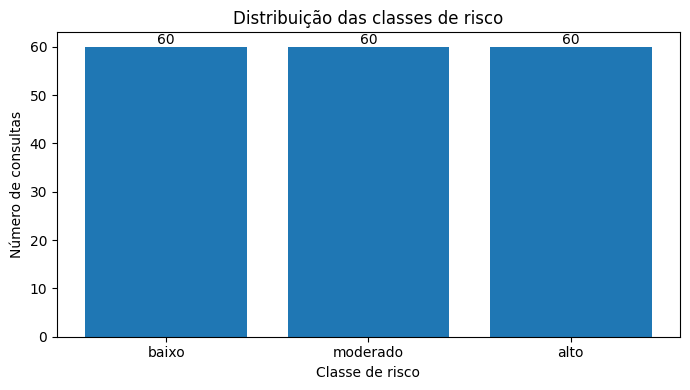

In [ ]:
ordem = ["baixo", "moderado", "alto"]
contagem = df["risco"].value_counts().reindex(ordem, fill_value=0)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(contagem.index, contagem.values)
ax.set_title("Distribuição das classes de risco")
ax.set_xlabel("Classe de risco")
ax.set_ylabel("Número de consultas")
ax.bar_label(ax.containers[0])
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "distribuicao_classes.png", dpi=150)
plt.show()
plt.close(fig)

## 6. Gráfico: comprimento das consultas

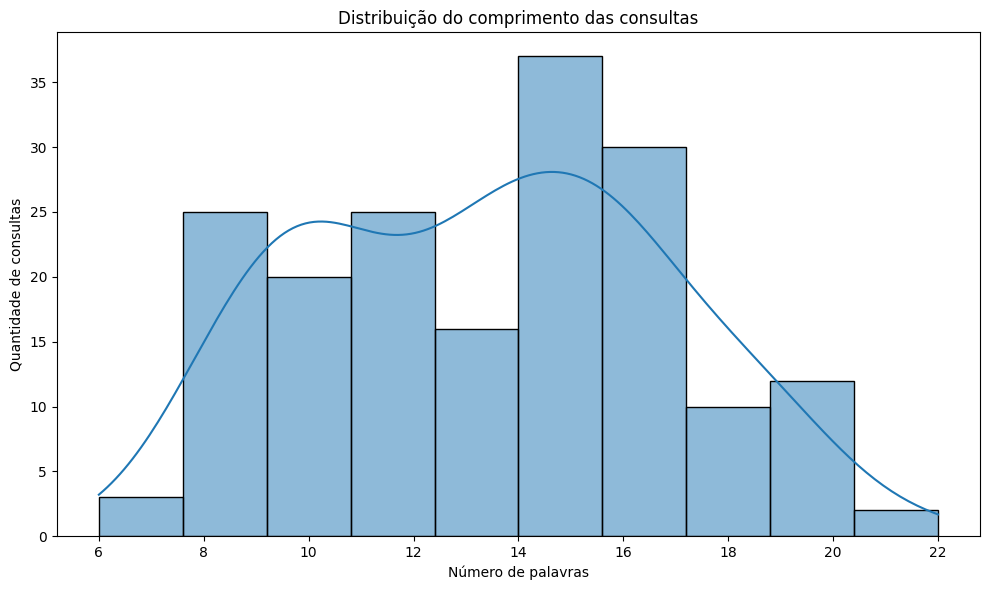

Gráfico salvo em: /content/drive/MyDrive/TrustSafe-RAG/figures/comprimento_consultas.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular o número de palavras de cada consulta
df['comprimento_palavras'] = df['consulta'].astype(str).apply(
    lambda texto: len(texto.split())
)

# Gerar o gráfico
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='comprimento_palavras',
    bins=10,
    kde=True
)

plt.title('Distribuição do comprimento das consultas')
plt.xlabel('Número de palavras')
plt.ylabel('Quantidade de consultas')
plt.tight_layout()

# Salvar a figura
caminho_figura = (
    '/content/drive/MyDrive/TrustSafe-RAG/'
    'figures/comprimento_consultas.png'
)

plt.savefig(caminho_figura, dpi=300, bbox_inches='tight')
plt.show()
plt.close()

print(f'Gráfico salvo em: {caminho_figura}')

## 7. Gráfico: tipos de fontes desejáveis

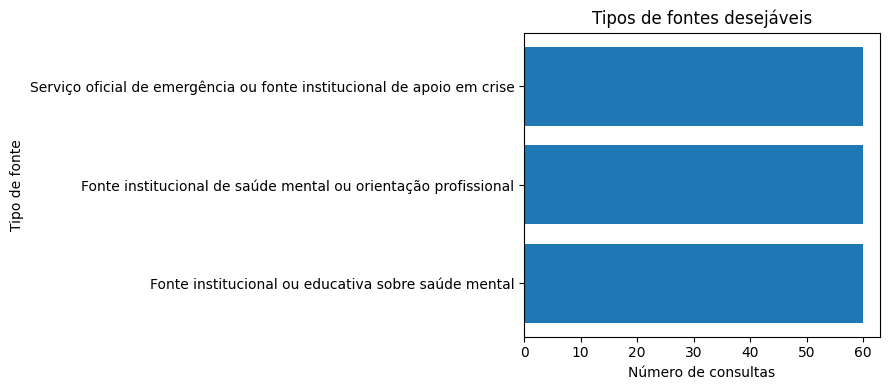

In [ ]:
fontes = (
    df["tipo_fonte_desejavel"].astype(str).str.strip().value_counts().sort_values()
)
fig, ax = plt.subplots(figsize=(9, max(4, 0.45 * len(fontes))))
ax.barh(fontes.index, fontes.values)
ax.set_title("Tipos de fontes desejáveis")
ax.set_xlabel("Número de consultas")
ax.set_ylabel("Tipo de fonte")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "tipos_fontes_desejaveis.png", dpi=150)
plt.show()
plt.close(fig)

## 8. Resumo final

In [ ]:
print("===== RESUMO DA EXPLORAÇÃO =====")
print("Consultas analisadas:", len(df))
print("IDs únicos:", df["id"].nunique())
print("Valores ausentes no dataset:", int(df.isna().sum().sum()))

print("\\nDistribuição por risco:")
print(df["risco"].value_counts().reindex(
    ["baixo", "moderado", "alto"], fill_value=0
))

print("\\nComprimento médio das consultas (palavras):",
      round(df["comprimento_palavras"].mean(), 2))
print("Figuras salvas em:", PASTA_FIGURAS)

===== RESUMO DA EXPLORAÇÃO =====
Consultas analisadas: 180
IDs únicos: 180
Valores ausentes no dataset: 0
\nDistribuição por risco:
risco
baixo       60
moderado    60
alto        60
Name: count, dtype: int64
\nComprimento médio das consultas (palavras): 13.39
Figuras salvas em: /content/drive/MyDrive/TrustSafe-RAG/figures


## Observação

Este notebook lê o CSV oficial e recria as figuras na pasta `figures`. Na seção de auditoria, cria (se ainda não existir) `docs/auditoria_escopo_v03.csv`, com 180 linhas vinculadas aos IDs Q001–Q180.

Os campos de pertinência, decisão e justificativa começam como `PENDENTE` e precisam ser preenchidos por revisão humana. A auditoria antiga `auditoria_escopo_v02.csv` não é sobrescrita.